In [59]:
import numpy as np
import hcipy as hp
import hcipy as hcipy
import matplotlib.pyplot as plt


Define constants, 

INIT pupil and aperture for Magellan, may change to MagAO-X

Supersample the pupil by factor 8 for more detail

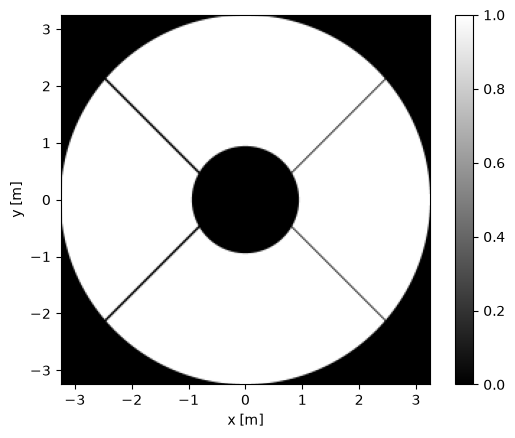

In [60]:
# Telescope / instrument constants
pupil_diameter = 6.5            # m
effective_focal_length = 71.5   # m

pupil_grid = hcipy.make_pupil_grid(256, diameter=pupil_diameter)

magellan_pupil_generator = hcipy.make_magellan_aperture() #TODO: change to MagAO-X pupil when needed?
telescope_pupil = hp.evaluate_supersampled(magellan_pupil_generator, pupil_grid, 8)

hcipy.imshow_field(telescope_pupil, cmap='gray')
plt.colorbar()
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.show()


Create and select the filters: 

- Narrowband 875 filter $\lambda$ = 875nm, bandwidth = 3\%
- Broadband z' filter (here z): $\lambda$ = 908nm, bandwidth = 14\%

In [61]:
# Define and select filter
filter_875 = {'name': '875 nm', 'wavelength': 875e-9, 'bandwidth': 0.03}
filter_z   = {'name': 'z band', 'wavelength': 908e-9, 'bandwidth': 0.14}

filter = filter_875
# filter = filter_z
wavelength = filter['wavelength']
bandwidth = filter['bandwidth']


Propagate a Monochomatic (at central wavelength of the filter) wavefront towards the focal plane.

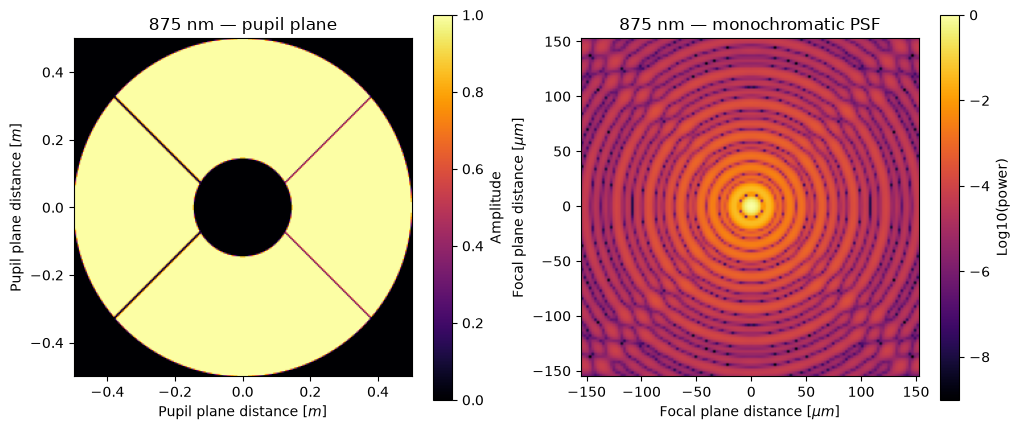

In [62]:
wavefront = hcipy.Wavefront(telescope_pupil, wavelength=wavelength) # create wavefront object

focal_grid = hcipy.make_focal_grid(q=4, num_airy=16, pupil_diameter=pupil_diameter,
                                    focal_length=effective_focal_length, reference_wavelength=wavelength)

fraun = hcipy.FraunhoferPropagator(pupil_grid, focal_grid, focal_length=effective_focal_length)

focal_image = fraun.forward(wavefront) #plot the monochromatic PSF

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].set_title('Pupil Plane')
ax[1].set_title('Focal Plane')

hcipy.imshow_field(wavefront.amplitude, grid_units = pupil_diameter, ax=ax[0], cmap='inferno')
ax[0].set_xlabel(r'Pupil plane distance [$m$]')
ax[0].set_ylabel(r'Pupil plane distance [$m$]')
ax[0].set_title(filter['name'] + ' — pupil plane')
ax[0].set_aspect('equal')
plt.colorbar(ax[0].images[0], ax=ax[0], label='Amplitude')

hcipy.imshow_field(np.log10(focal_image.intensity / focal_image.intensity.max()), grid_units=1e-6, ax=ax[1],cmap='inferno')
ax[1].set_xlabel(r'Focal plane distance [$\mu m$]')
ax[1].set_ylabel(r'Focal plane distance [$\mu m$]')
ax[1].set_title(filter['name'] + ' — monochromatic PSF')
ax[1].set_aspect('equal')

plt.colorbar(ax[1].images[0], ax=ax[1], label='Log10(power)')
plt.show()


Add the filter bandwidth to the wavefront before propagating.

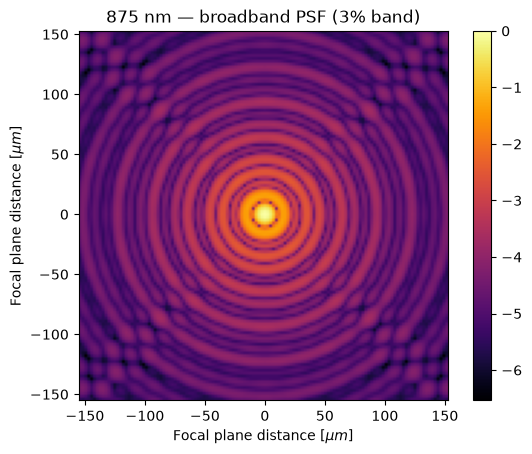

In [63]:
focal_total = 0
for wlen in wavelength * np.linspace(1 - bandwidth / 2., 1 + bandwidth / 2., 11):
    wavefront = hcipy.Wavefront(telescope_pupil, wlen)
    focal_total += fraun.forward(wavefront).power

hcipy.imshow_field(np.log10(focal_total / focal_total.max()), grid_units=1e-6, cmap='inferno')

plt.colorbar()
plt.xlabel(r'Focal plane distance [$\mu m$]')
plt.ylabel(r'Focal plane distance [$\mu m$]')
plt.title(filter['name'] + ' — broadband PSF ({:.0f}% band)'.format(bandwidth * 100))
plt.show()


# TODO:  Finish Tutorials, simulate the fPIAA and iPIAA lenses
